# UC2 · Jalon 4 — Les sessions comme des séquences
 **Groupe 13 · Master SDIA-2 · ENSET Mohammedia**  
 Agrigah Aya · AARAB Mustapha · Toubani Badr Eddine

 Comparer GRU/LSTM aux comptages, vérifier le masquage et la longueur, et tester si l’ordre des mots des descriptions apporte de l’information.

 **Données officielles :** les quatre fichiers NPZ du dossier `Use Cases.rar`,
 partitions imposées conservées. Fashion-MNIST fournit les images ; descriptions,
 prix, boutique B et sessions sont des données pédagogiques simulées. Nous
 n'affirmons pas entraîner un système de production sur de vraies ventes.

 Le projet Kaggle antérieur reste dans `annexes/historique_kaggle`. Il ne possède
 pas les prix/sessions ni les partitions imposées. Ses scores ne sont pas mêlés
 aux résultats de cette remise. Le groupe a utilisé une assistance IA pour le
 code, la rédaction et les contrôles ; les sorties chiffrées sont calculées.

## Exécution et fichiers à conserver
 1. Décompresser **toute** l'archive, garder `data_UC2/` et `src/` avec les notebooks.
 2. Suivre le README pour l'environnement Python 3.12, TensorFlow 2.20 / Keras 3.11.3.
 3. VS Code : extensions Python/Jupyter, choisir `.venv-uc2` comme noyau. Colab :
    GPU facultatif, placer le dossier complet dans Drive puis ouvrir ce notebook.
 4. Exécuter dans l'ordre. Les modèles livrés sont réutilisés lorsqu'ils sont compatibles.
    Pour une nouvelle exécution indépendante, renseigner `RUN_LABEL` ci-dessous.
 5. Sauvegarder le notebook avec sorties. Les modèles, courbes, journal et décisions
    s'enregistrent dans `artifacts/jalonN/` (ou `reruns/RUN_LABEL/jalonN/`).

 Tous les réglages précèdent l'ouverture du test. La session finale est figée par
 empreintes des poids et de la configuration. Une relance lit les résultats
 finalisés. Ne pas modifier un modèle/seuil après accès au test pour améliorer
 artificiellement le score. Les comparateurs fixés sont évalués dans cette même
 session finale. Le temps mesuré dépend du matériel et exclut l'installation.

In [1]:
import os,sys,subprocess
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL","2")
assert (3,10)<=sys.version_info[:2]<=(3,13), "Utiliser Python 3.12."
# Configuration facultative avant exécution, pas après le test.
PROJECT_DIR = None  # Colab : "/content/drive/MyDrive/GroupeXX_UC2"
RUN_LABEL = ""      # ex. "reproduction_cpu" pour un nouveau dossier de résultats
if PROJECT_DIR:
    ROOT=Path(PROJECT_DIR).expanduser().resolve()
else:
    candidates=[Path.cwd(),Path.cwd().parent]
    ROOT=next((p for p in candidates if (p/"data_UC2/uc2_catalogueA.npz").exists()),None)
    if ROOT is None:raise FileNotFoundError("Ouvrir le dossier complet de l'archive ou définir PROJECT_DIR.")
sys.path.insert(0,str(ROOT/"src"))
from uc2_utils import *
from tensorflow.keras import layers
CFG={'epochs': 20, 'batch': 256, 'patience': 4, 'units': 32, 'embedding_type': 8, 'embedding_category': 8, 'coupon_fraction': 0.1, 'purchase_selection': 'validation P@10%, tie exact AUC then parameters', 'text_selection': 'macro F1 val', 'text_max_words': 500, 'text_length': 25, 'shuffle_seed': 242}
OUT,ENV,DATA_SHA=initialise(ROOT,4,CFG,RUN_LABEL)
display(pd.DataFrame([ENV]).T.rename(columns={0:"Valeur"}))
print("Dossier :",ROOT,"| résultats :",OUT)
print("GPU :",ENV["devices"] or "CPU (4 threads)")

Dossier : /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2 | résultats : /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2/artifacts/jalon4
GPU : CPU (4 threads)


,Valeur
python,"3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 2..."
platform,Linux-6.18.44-x86_64-with-glibc2.39
tensorflow,2.20.0
keras,3.11.3
devices,[]
cpu_threads,4
seed,42
numpy,2.3.5
pandas,2.2.3
scipy,1.17.0


## 1. Quatre expériences séquentielles et contrôle de l'ordre
 GRU32 et LSTM32, chacun **avec et sans masquage**. Embeddings : types 6×8,
 catégories 11×8, puis gamme de prix/durée normalisées, soit 18 variables par
 événement. Seuls les événements réels de train ajustent le normaliseur.
 Les valeurs numériques du padding sont remises à zéro après transformation.
 Les embeddings ne propagent pas de masque implicitement : seul le facteur
 `masked` active le masque explicite `type != 0` dans la couche récurrente.

 La référence logistique de comptages reste C=1. Les checkpoints récurrents
 utilisent AUC val pour arrêt, puis le modèle candidat est choisi par **P@10% val**,
 égalité AUC puis taille. Pas de consultation du test durant cette sélection.

 Descriptions : BoW169+MLP, LSTM à mots ordonnés, LSTM à mots permutés avec les
 **mêmes tokens et architecture**. La permutation conserve la multiplicité des
 mots et le padding. Elle isole l'ordre plus directement qu'une simple comparaison
 de deux architectures/tokenisations. Tokenizer adapté sur train seulement.

 **Coupons :** à budget exactement 10%, top-k des scores décroissants (égalité
 indice de ligne). Choisir la meilleure précision val à ce budget, puis figer un
 seuil de score au bord des 10%. Le seuil numérique seul peut produire une autre
 couverture sur test ; on rapporte aussi celle-ci. Un seuil très haut ciblant 1%
 n'est pas une solution à la consigne des 10%.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
import joblib
A=load_catalogue(ROOT,'A');S=load_sessions(ROOT);BOW=fit_bow(A)
write_json(OUT/'bow_vocabulary.json',BOW.vocabulary_)
SY={s:S['achat_'+s] for s in ['train','val']}
valid=S['type_train']!=0
raw=np.stack([S['prix_train'].astype('float32')/5.,S['duree_train'].astype('float32')],axis=-1)
NUM_SCALER=StandardScaler().fit(raw[valid]);joblib.dump(NUM_SCALER,OUT/'event_numeric_scaler.joblib')
def sequence_input(d,s):
    types=d['type_'+s].astype('int32');cats=d['categorie_'+s].astype('int32');mask=types!=0
    length=d['longueur_'+s].astype(int)
    assert np.array_equal(mask,np.arange(60)[None,:]<length[:,None])
    numeric=np.stack([d['prix_'+s].astype('float32')/5.,d['duree_'+s].astype('float32')],axis=-1)
    numeric=NUM_SCALER.transform(numeric.reshape(-1,2)).reshape(numeric.shape).astype('float32')
    numeric[~mask]=0.
    return {'type':types,'categorie':cats,'numerique':numeric}
SX={s:sequence_input(S,s) for s in ['train','val']}
SUMMARY=pd.DataFrame([{'split':s,'rows':len(SY[s]),'positive_rate':float(SY[s].mean()),
    'mean_length':float(S['longueur_'+s].mean()),'padding_fraction':float(np.mean(S['type_'+s]==0))} for s in ['train','val']])
display(SUMMARY);SUMMARY.to_csv(OUT/'session_distribution.csv',index=False)
LR=make_pipeline(StandardScaler(),LogisticRegression(C=1.,max_iter=1000,random_state=42))
LR.fit(session_features(S,'train'),SY['train']);joblib.dump(LR,OUT/'logistic_reference.joblib')
LR_VAL=session_metrics(SY['val'],LR.predict_proba(session_features(S,'val'))[:,1]);journal(OUT,'logistic_counts','validation','measured',**LR_VAL)
print('Entrée numérique / masque / embeddings :',SX['train']['numerique'].shape,valid.shape)

Entrée numérique / masque / embeddings : (20000, 60, 2) (20000, 60)


,split,rows,positive_rate,mean_length,padding_fraction
0,train,20000,0.26635,20.35545,0.660743
1,val,4000,0.27525,20.21450,0.663092


## 2. Vérifications théoriques et causalité
 GRU Keras `reset_after=True`, entrée d=10, unités u=32 : trois portes,
 `3×(du+u²+2u) = 3×(320+1024+64) = 4 224` paramètres. Deux vecteurs de biais
 par porte dans cette formulation. Avec nos 18 entrées : 4 992 paramètres pour
 le GRU seul, plus embeddings et sortie. On vérifie le cas demandé d=10.

 20 événements complétés à 60 : 40/60 = **66,67% padding**. Sans masque, les
 portes récurrentes continuent d'actualiser l'état pendant les pas artificiels,
 même si leurs valeurs numériques sont nulles. Les embeddings PAD sont aussi
 des vecteurs appris. Avec masque, ces pas n'actualisent pas l'état utile.

 Un bidirectionnel sur une **session complète** utilise des événements futurs
 par rapport à une décision coupon en cours de navigation, donc viole ce
 scénario causal. Il peut techniquement fonctionner sur le seul préfixe déjà
 observé, mais la passe arrière doit être recalculée et cela ne démontre pas
 une performance en ligne. Un modèle unidirectionnel permet un état causal
 incrémental. Sessions <5 événements : différer le coupon, afficher un score
 provisoire ; le seuil appris sur sessions complètes n'est pas validé pour ces
 visiteurs. Les diagnostics de préfixe ci-dessous exposent cette limite.

Retenu : GRU_unmasked | seuil validation10% : 0.7109094262123108


,model,auc,average_precision,precision_top10,targeted_rows,positive_rate,parameters,seconds,trainable_parameters,best_epoch,kind,masked
0,logistic_counts,0.778188,0.529004,0.5775,400,0.27525,6,0.000000,NaN,NaN,NaN,NaN
1,GRU_masked,0.836077,0.672237,0.7950,400,0.27525,5161,110.345212,5161.0,15.0,GRU,True
2,GRU_unmasked,0.833703,0.678865,0.8050,400,0.27525,5161,115.017420,5161.0,18.0,GRU,False
3,LSTM_masked,0.837064,0.675555,0.7900,400,0.27525,6697,94.488793,6697.0,15.0,LSTM,True
4,LSTM_unmasked,0.831096,0.665204,0.7825,400,0.27525,6697,76.665838,6697.0,20.0,LSTM,False


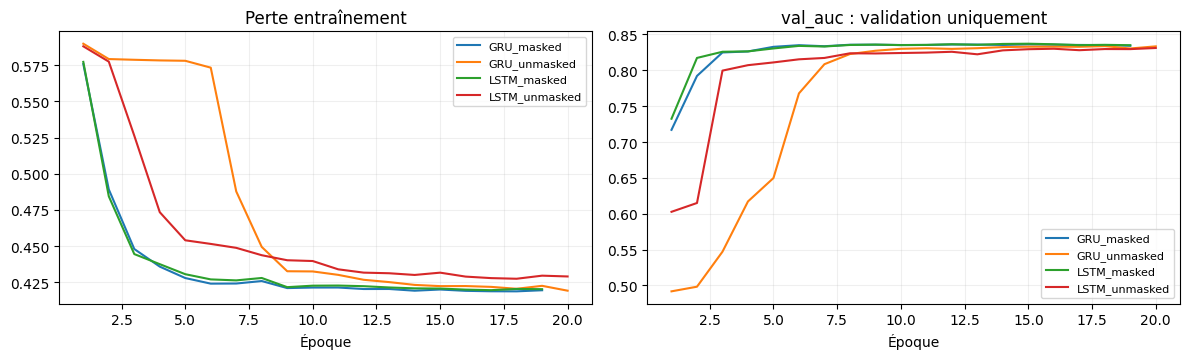

In [3]:
theory=layers.GRU(32,reset_after=True);theory.build((None,60,10));assert theory.count_params()==4224
write_json(OUT/'theory_checks.json',{'gru_32_input10_parameters':theory.count_params(),'padding_fraction_20_of_60':40/60,
    'actual_input_features':18,'actual_gru_layer_parameters':4992})
def purchase_recurrent(kind='GRU',masked=True):
    type_in=keras.Input((None,),dtype='int32',name='type');cat_in=keras.Input((None,),dtype='int32',name='categorie')
    num_in=keras.Input((None,2),name='numerique')
    t=layers.Embedding(6,8,mask_zero=False,name='type_embedding')(type_in)
    c=layers.Embedding(11,8,mask_zero=False,name='category_embedding')(cat_in)
    x=layers.Concatenate()([t,c,num_in]);mask=keras.ops.not_equal(type_in,0) if masked else None
    recurrent=layers.GRU(32,reset_after=True,name='recurrent') if kind=='GRU' else layers.LSTM(32,name='recurrent')
    x=recurrent(x,mask=mask);x=layers.Dropout(.2)(x)
    m=keras.Model({'type':type_in,'categorie':cat_in,'numerique':num_in},layers.Dense(1,activation='sigmoid')(x))
    m.compile(keras.optimizers.Adam(1e-3),'binary_crossentropy');return m
PURCHASE_MODELS={};purchase_rows=[];VAL_SCORES={}
for kind in ['GRU','LSTM']:
    for masked in [True,False]:
        name=kind+('_masked' if masked else '_unmasked')
        m,info=fit_model(OUT,name,lambda k=kind,m=masked:purchase_recurrent(k,m),SX['train'],SY['train'],SX['val'],SY['val'],
            epochs=CFG['epochs'],batch=CFG['batch'],monitor='val_auc',mode='max',
            evaluator=lambda p:{'val_auc':session_metrics(SY['val'],p)['auc'],'val_p10':session_metrics(SY['val'],p)['precision_top10']})
        PURCHASE_MODELS[name]=m;VAL_SCORES[name]=predict(m,SX['val']).ravel()
        purchase_rows.append(validation_row(OUT,name,info,session_metrics(SY['val'],VAL_SCORES[name]),kind=kind,masked=masked))
PURCHASE_VAL=write_table(OUT,'purchase_validation',[{'model':'logistic_counts',**LR_VAL,'parameters':6,'seconds':0.},*purchase_rows])
eligible=PURCHASE_VAL[PURCHASE_VAL.model!='logistic_counts']
SELECTED_PURCHASE=eligible.sort_values(['precision_top10','auc','parameters'],ascending=[False,False,True]).iloc[0].model
SELECTED_PV=VAL_SCORES[SELECTED_PURCHASE]
COUPON_THRESHOLD=float(SELECTED_PV[top_indices(SELECTED_PV)][-1])
write_json(OUT/'coupon_policy.json',{'fraction':.1,'score_threshold_val':COUPON_THRESHOLD,'tie_rule':'score descending then row index',
     'batch_policy':'exactly ceil(.1*N) rows','online_limit':'validation on complete sessions, not validated for arbitrary prefixes'})
learning_curves(OUT,list(PURCHASE_MODELS),'val_auc','purchase_learning.png')
print('Retenu :',SELECTED_PURCHASE,'| seuil validation10% :',COUPON_THRESHOLD)

,model,length_band,rows,positive_rate,auc,brier_error,error_at_fixed_0p5
0,GRU_masked,4–9,1151,0.190269,0.832138,0.109128,0.148566
1,GRU_masked,10–19,1255,0.262948,0.836324,0.135535,0.195219
2,GRU_masked,20–39,1097,0.331814,0.827294,0.152767,0.214221
3,GRU_masked,40–60,497,0.378270,0.794447,0.173604,0.265594
4,GRU_unmasked,4–9,1151,0.190269,0.829389,0.109604,0.147698
5,GRU_unmasked,10–19,1255,0.262948,0.836049,0.137060,0.194422
6,GRU_unmasked,20–39,1097,0.331814,0.823355,0.155857,0.225160
7,GRU_unmasked,40–60,497,0.378270,0.784704,0.180228,0.289738
8,LSTM_masked,4–9,1151,0.190269,0.830151,0.109219,0.150304
9,LSTM_masked,10–19,1255,0.262948,0.837910,0.135337,0.190438


,model,max_probability_difference_padding60_to80
0,GRU_masked,0.000000
1,GRU_unmasked,0.065901
2,LSTM_masked,0.000000
3,LSTM_unmasked,0.159214


,auc,average_precision,precision_top10,targeted_rows,positive_rate
ordered,0.833703,0.678865,0.8050,400.0,0.27525
permuted_events_same_frozen_model,0.744450,0.465954,0.4775,400.0,0.27525


,observed_events_max,auc,average_precision,precision_top10,targeted_rows,positive_rate
0,3,0.532139,0.313694,0.3850,400,0.27525
1,5,0.584106,0.362157,0.4600,400,0.27525
2,10,0.647407,0.411139,0.5075,400,0.27525
3,20,0.747818,0.534097,0.6375,400,0.27525
4,60,0.833703,0.678865,0.8050,400,0.27525


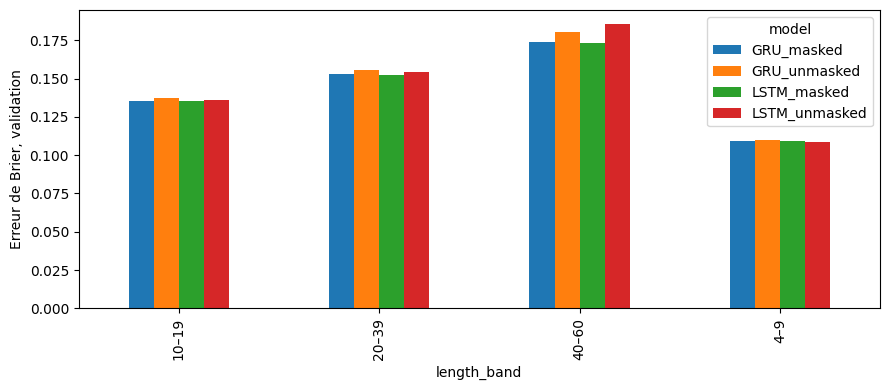

In [4]:
lengths=S['longueur_val'].astype(int);bands=pd.cut(lengths,[0,9,19,39,60],labels=['4–9','10–19','20–39','40–60'])
rows=[]
for name,p in VAL_SCORES.items():
    for band in bands.categories:
        i=np.flatnonzero(bands==band)
        rows.append({'model':name,'length_band':str(band),'rows':len(i),'positive_rate':float(SY['val'][i].mean()),
            'auc':float(roc_auc_score(SY['val'][i],p[i])),'brier_error':float(np.mean((p[i]-SY['val'][i])**2)),
            'error_at_fixed_0p5':float(np.mean((p[i]>=.5)!=SY['val'][i]))})
LENGTH_VAL=write_table(OUT,'length_error_validation',rows)
# Même séquence réelle, padding supplémentaire : test structurel sur validation.
short={k:v[:32] for k,v in SX['val'].items()}
extended={k:np.pad(v,[(0,0),(0,20)]+([(0,0)] if v.ndim==3 else [])) for k,v in short.items()}
invariance=[]
for name,m in PURCHASE_MODELS.items():
    delta=float(np.max(np.abs(predict(m,short)-predict(m,extended))))
    invariance.append({'model':name,'max_probability_difference_padding60_to80':delta})
    if name.endswith('_masked'):assert delta<1e-5
display(pd.DataFrame(invariance));write_json(OUT/'padding_invariance_validation.json',invariance)
# Permutation simultanée de tous les champs de chaque événement, pas seulement du type.
shuffled={k:v.copy() for k,v in SX['val'].items()};rng=np.random.default_rng(CFG['shuffle_seed'])
for i,L in enumerate(lengths):
    order=rng.permutation(L)
    for key in shuffled:shuffled[key][i,:L]=SX['val'][key][i,order]
ORDER_VAL={'ordered':session_metrics(SY['val'],SELECTED_PV),
           'permuted_events_same_frozen_model':session_metrics(SY['val'],predict(PURCHASE_MODELS[SELECTED_PURCHASE],shuffled))}
display(pd.DataFrame(ORDER_VAL).T);write_json(OUT/'event_order_validation.json',ORDER_VAL)
prefix_rows=[]
for cutoff in [3,5,10,20,60]:
    prefix={k:v.copy() for k,v in SX['val'].items()}
    for key in prefix:prefix[key][:,cutoff:]=0
    metrics=session_metrics(SY['val'],predict(PURCHASE_MODELS[SELECTED_PURCHASE],prefix))
    prefix_rows.append({'observed_events_max':cutoff,**metrics})
PREFIX_VAL=write_table(OUT,'prefix_validation_diagnostic',prefix_rows)
fig,ax=plt.subplots(figsize=(9,4));LENGTH_VAL.pivot(index='length_band',columns='model',values='brier_error').plot.bar(ax=ax)
ax.set_ylabel('Erreur de Brier, validation');fig.tight_layout();fig.savefig(OUT/'mask_length_errors.png',dpi=150);plt.show();plt.close(fig)

## 3. Descriptions séquentielles : LSTM versus sac de mots
 Les descriptions sont simulées et souvent des listes d'attributs ou formulations
 promotionnelles. Une amélioration de LSTM ne suffit pas à prouver un effet de
 l'ordre. L'essai permuté conserve les mêmes mots et le même réseau. Les
 différences de tokenisation BoW/LSTM sont exportées et limitent la comparaison
 brute entre architectures. Une description vide utilise un token inconnu unique
 dans le LSTM pour éviter un lot entièrement masqué sur GPU ; le BoW reste nul.

,model,macro_f1,accuracy,parameters,trainable_parameters,seconds,best_epoch,tokenization
0,BoW_MLP,0.753396,0.74575,11530,11530,5.292021,16,BoW169
1,LSTM_words_ordered,0.751269,0.74400,14282,14282,40.023853,17,TextVectorization vocab=176
2,LSTM_words_shuffled,0.747471,0.73950,14282,14282,24.663353,8,TextVectorization vocab=176


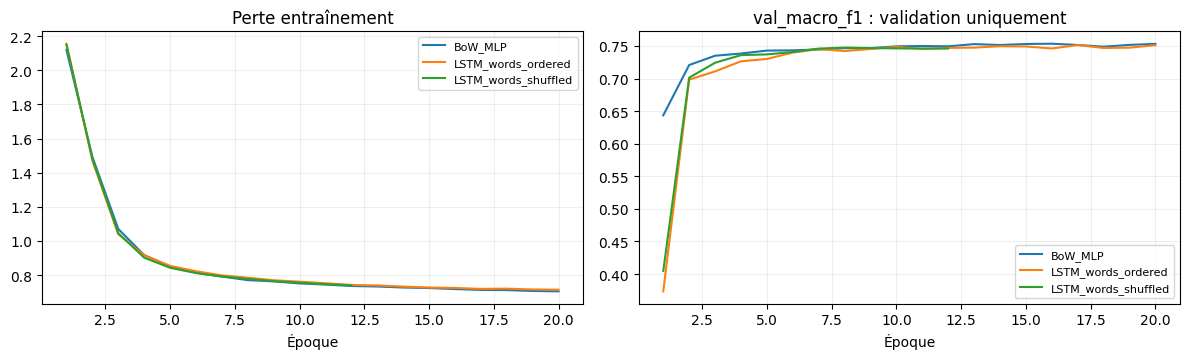

In [5]:
VECT=layers.TextVectorization(max_tokens=500,output_sequence_length=25)
VECT.adapt(tf.constant(A['description_train'].tolist()))
vocab=VECT.get_vocabulary();write_json(OUT/'text_sequence_vocabulary.json',vocab)
def text_tokens(d,s):
    x=VECT(tf.constant(d['description_'+s].tolist())).numpy().astype('int32')
    x[~np.any(x!=0,axis=1),0]=1
    return x
TOKENS={s:text_tokens(A,s) for s in ['train','val']}
def shuffled_words(tokens,seed):
    x=tokens.copy();rng=np.random.default_rng(seed)
    for i in range(len(x)):
        L=int(np.sum(x[i]!=0));x[i,:L]=x[i,rng.permutation(L)]
    return x
SHUFFLED={s:shuffled_words(TOKENS[s],CFG['shuffle_seed']+(0 if s=='train' else 1)) for s in ['train','val']}
BOW_X={s:bow_input(BOW,A,s) for s in ['train','val']};AY={s:A['categorie_'+s] for s in ['train','val']}
def word_model(kind):
    if kind=='bow':
        inp=keras.Input((169,));x=layers.Dense(64,activation='relu')(inp)
    else:
        inp=keras.Input((25,),dtype='int32');x=layers.Embedding(len(vocab),32,mask_zero=True)(inp);x=layers.LSTM(32)(x)
    x=layers.Dropout(.3)(x);m=keras.Model(inp,layers.Dense(10,activation='softmax')(x))
    m.compile(keras.optimizers.Adam(1e-3),'sparse_categorical_crossentropy');return m
TEXT_MODELS={};TEXT_INPUT={};text_rows=[]
for name,kind,x in [('BoW_MLP','bow',BOW_X),('LSTM_words_ordered','lstm',TOKENS),('LSTM_words_shuffled','lstm',SHUFFLED)]:
    m,info=fit_model(OUT,name,lambda k=kind:word_model(k),x['train'],AY['train'],x['val'],AY['val'],epochs=CFG['epochs'],batch=CFG['batch'],
        monitor='val_macro_f1',mode='max',evaluator=lambda p:{'val_macro_f1':classifier_metrics(AY['val'],p)['macro_f1']})
    TEXT_MODELS[name]=m;TEXT_INPUT[name]=x
    text_rows.append(validation_row(OUT,name,info,classifier_metrics(AY['val'],predict(m,x['val'])),tokenization='BoW169' if kind=='bow' else f'TextVectorization vocab={len(vocab)}'))
TEXT_VAL=write_table(OUT,'text_validation',text_rows)
SELECTED_TEXT=TEXT_VAL.sort_values(['macro_f1','parameters'],ascending=[False,True]).iloc[0].model
# Perturbation d'ordre du même LSTM ordonné, distincte de l'entraînement permuté.
perturb=classifier_metrics(AY['val'],predict(TEXT_MODELS['LSTM_words_ordered'],SHUFFLED['val']))
write_json(OUT/'word_order_validation_diagnostic.json',{'same_ordered_lstm_shuffled_val':perturb,'train_only_vocabulary':True})
learning_curves(OUT,list(TEXT_MODELS),'val_macro_f1','text_learning.png')

In [6]:
coupon_rows=[]
for fraction in [.02,.05,.10,.15,.20]:
    idx=top_indices(SELECTED_PV,fraction);tau=float(SELECTED_PV[idx][-1])
    coupon_rows.append({'fraction':fraction,'rows':len(idx),'score_threshold':tau,'buyers_fraction':float(SY['val'][idx].mean())})
COUPON_VAL=write_table(OUT,'coupon_capacity_validation',coupon_rows)
print('Budget de la consigne : exactement 10%, soit',len(top_indices(SELECTED_PV)),'sessions val.')
print('Un gain à 2% ou 5% ne satisfait pas ce budget. Le seuil coupon val est figé :',COUPON_THRESHOLD)

Budget de la consigne : exactement 10%, soit 400 sessions val.
Un gain à 2% ou 5% ne satisfait pas ce budget. Le seuil coupon val est figé : 0.7109094262123108


,fraction,rows,score_threshold,buyers_fraction
0,0.02,80,0.846075,0.925000
1,0.05,200,0.799075,0.870000
2,0.10,400,0.710909,0.805000
3,0.15,600,0.638187,0.733333
4,0.20,800,0.581653,0.685000


In [7]:
selection={'purchase':SELECTED_PURCHASE,'text':SELECTED_TEXT,'coupon_threshold_val':round(COUPON_THRESHOLD,8),
     'coupon_fraction':.1,'fixed_comparators':['logistic_counts','BoW_MLP'],
     'models':sorted(set([SELECTED_PURCHASE,SELECTED_TEXT,'BoW_MLP'])),'logistic_sha':sha_file(OUT/'logistic_reference.joblib')}
def evaluate_final():
    st=load_sessions(ROOT,('test',));at=load_catalogue(ROOT,'A',('test',))
    sx=sequence_input(st,'test');prob=predict(PURCHASE_MODELS[SELECTED_PURCHASE],sx).ravel()
    plr=LR.predict_proba(session_features(st,'test'))[:,1]
    bow=bow_input(BOW,at,'test');tokens=text_tokens(at,'test')
    text_x=bow if SELECTED_TEXT=='BoW_MLP' else shuffled_words(tokens,CFG['shuffle_seed']+2) if SELECTED_TEXT=='LSTM_words_shuffled' else tokens
    tp=predict(TEXT_MODELS[SELECTED_TEXT],text_x);bp=predict(TEXT_MODELS['BoW_MLP'],bow)
    fixed_target=prob>=COUPON_THRESHOLD
    fixed_metric={'fixed_threshold_coverage':float(fixed_target.mean()),'fixed_threshold_precision':float(st['achat_test'][fixed_target].mean()) if fixed_target.any() else None,
         'fixed_threshold_targeted_rows':int(fixed_target.sum())}
    idx=top_indices(prob);target=np.zeros(len(prob),dtype=bool);target[idx]=True
    pd.DataFrame({'row':np.arange(len(prob)),'score':prob,'target_top10':target,'target_fixed_threshold':fixed_target,'buyer':st['achat_test']}).to_csv(OUT/'test_coupon_predictions.csv',index=False)
    np.savez_compressed(OUT/'test_predictions.npz',purchase_probability=prob,logistic_probability=plr,purchase_true=st['achat_test'],session_length=st['longueur_test'],
        text_probability=tp,bow_probability=bp,category_true=at['categorie_test'])
    return {'purchase':{'model':SELECTED_PURCHASE,**session_metrics(st['achat_test'],prob)},'logistic_reference':session_metrics(st['achat_test'],plr),
        'coupon_fixed_val_threshold':fixed_metric,'text_category':{'model':SELECTED_TEXT,**classifier_metrics(at['categorie_test'],tp)},
        'bow_reference':classifier_metrics(at['categorie_test'],bp)}
TEST=test_once(OUT,selection,evaluate_final);display(pd.DataFrame(TEST).T)

,model,auc,average_precision,precision_top10,targeted_rows,positive_rate,fixed_threshold_coverage,fixed_threshold_precision,fixed_threshold_targeted_rows,macro_f1,accuracy
purchase,GRU_unmasked,0.836124,0.670154,0.798333,600,0.2665,NaN,NaN,NaN,NaN,NaN
logistic_reference,NaN,0.781611,0.517853,0.595,600.0,0.2665,NaN,NaN,NaN,NaN,NaN
coupon_fixed_val_threshold,NaN,NaN,NaN,NaN,NaN,NaN,0.100667,0.798013,604.0,NaN,NaN
text_category,BoW_MLP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.747068,0.739667
bow_reference,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.747068,0.739667


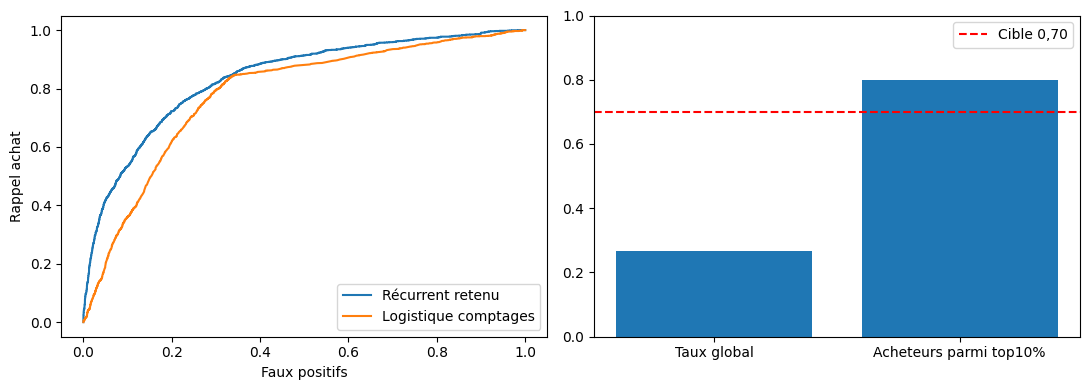

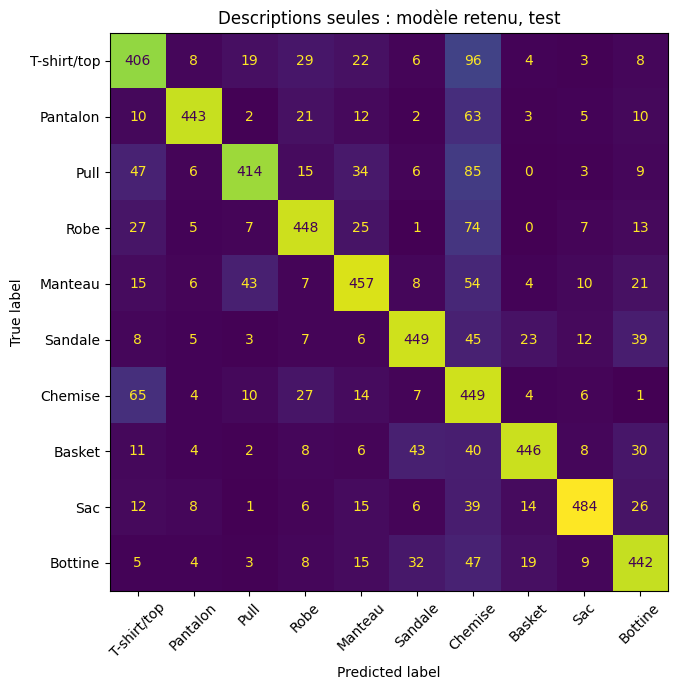

,length_band,rows,auc,brier_error,coupon_targeted,purchase_rate
0,4–9,1749,0.849101,0.104748,118,0.193825
1,10–19,1847,0.833305,0.139405,185,0.276665
2,20–39,1655,0.816818,0.157081,196,0.300906
3,40–60,749,0.813045,0.170369,101,0.335113


In [8]:
z=np.load(OUT/'test_predictions.npz')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,key in [('Récurrent retenu','purchase_probability'),('Logistique comptages','logistic_probability')]:
    fpr,tpr,_=roc_curve(z['purchase_true'],z[key]);axes[0].plot(fpr,tpr,label=name)
axes[0].legend();axes[0].set(xlabel='Faux positifs',ylabel='Rappel achat')
coupon=pd.read_csv(OUT/'test_coupon_predictions.csv');axes[1].bar(['Taux global','Acheteurs parmi top10%'],[z['purchase_true'].mean(),TEST['purchase']['precision_top10']])
axes[1].axhline(.70,color='red',ls='--',label='Cible 0,70');axes[1].set_ylim(0,1);axes[1].legend()
fig.tight_layout();fig.savefig(OUT/'purchase_test_roc_and_coupons.png',dpi=150);plt.show();plt.close(fig)
show_confusion(z['category_true'],z['text_probability'],OUT,filename='text_confusion_test.png',title='Descriptions seules : modèle retenu, test')
bands=pd.cut(z['session_length'],[0,9,19,39,60],labels=['4–9','10–19','20–39','40–60']);rows=[]
for band in bands.categories:
    i=np.flatnonzero(bands==band);p=z['purchase_probability'][i];y=z['purchase_true'][i]
    rows.append({'length_band':str(band),'rows':len(i),'auc':float(roc_auc_score(y,p)),'brier_error':float(np.mean((p-y)**2)),
        'coupon_targeted':int(coupon.target_top10.values[i].sum()),'purchase_rate':float(y.mean())})
TEST_LENGTH=write_table(OUT,'test_length_errors',rows)
write_json(OUT/'test_confidence_intervals.json',{'purchase_auc_95pct':relative_ci(z['purchase_true'],z['purchase_probability'],lambda y,p:roc_auc_score(y,p)),
    'precision_top10_95pct':relative_ci(z['purchase_true'],z['purchase_probability'],lambda y,p:session_metrics(y,p)['precision_top10']),
    'resamples':300,'method':'row bootstrap, no model or threshold retuning'})

### Modèle retenu et limite du remplissage fixe
La règle annoncée sélectionne **GRU sans masque**, car sa P@10% val est la
plus élevée. Ce résultat ne justifie pas de retirer le masque en production :
ajouter 20 PAD change sa probabilité jusqu'à **0,0659**, contre **0** pour le
GRU masqué. Le gain dépend possiblement du raccourci de longueur et du format
fixe 60. Les modèles masqués restent disponibles et comparés sur validation.
Le BoW gagne aussi la sélection texte : les LSTM ne sont pas forcés comme
vainqueurs. En test, 479 acheteurs figurent parmi 600 sessions ciblées ; le
seuil numérique val cible 604 sessions, ce qui est rapporté séparément.
Ces scores sur sessions complètes ne valident pas un ciblage prospectif en ligne.


In [9]:
ordered=TEXT_VAL.set_index('model').loc['LSTM_words_ordered'];shuffled=TEXT_VAL.set_index('model').loc['LSTM_words_shuffled']
mask_msg='Les variantes avec et sans masque sont dans purchase_validation.csv ; ne pas supposer que le masque améliore toujours l’AUC, le padding peut aussi servir de raccourci de longueur.'
decision=f"""# Décisions Jalon 4
Groupe XX, UC2. Agrigah Aya, AARAB Mustapha, Toubani Badr Eddine.

**Achat retenu :** {SELECTED_PURCHASE}, sélection sur P@10% validation, égalité AUC/taille. Test AUC={TEST['purchase']['auc']:.4f}, P@10%={TEST['purchase']['precision_top10']:.4f}. Logistique : AUC={TEST['logistic_reference']['auc']:.4f}, P@10%={TEST['logistic_reference']['precision_top10']:.4f}. Écarts aux références 0,82 / 0,70 : {TEST['purchase']['auc']-.82:+.4f} / {TEST['purchase']['precision_top10']-.70:+.4f}. Sigmoid/CE binaire, checkpoints sur AUC val, 20 époques maximum. {mask_msg}

**Masquage et longueur :** invariance structurelle du modèle masqué à 20 pas PAD supplémentaires vérifiée sur validation. Erreurs/AUC par longueur dans les tableaux val/test. Sans masque, des portes et embeddings PAD peuvent altérer l'état ou encoder indirectement la longueur. La longueur corrélée à l'achat peut favoriser cette stratégie sur données simulées sans prouver un avantage causal en production.

**Coupons :** seuil score val={COUPON_THRESHOLD:.8f}, 10% fixés. Dans un lot test, sélectionner exactement {TEST['purchase']['targeted_rows']} / 6 000 par rang décroissant, égalité indice. Le seuil numérique fixe couvre {TEST['coupon_fixed_val_threshold']['fixed_threshold_coverage']:.4f} du test, précision={TEST['coupon_fixed_val_threshold']['fixed_threshold_precision']}. Il est calibré sur des sessions complètes, pas sur un préfixe arbitraire. Aucune étiquette test n'a choisi le seuil ni les personnes ciblées.

**Descriptions :** retenu {SELECTED_TEXT}, F1 texte seul test={TEST['text_category']['macro_f1']:.4f}, BoW fixé={TEST['bow_reference']['macro_f1']:.4f}. Ordonné versus permuté sur validation : {ordered.macro_f1:.4f} / {shuffled.macro_f1:.4f}, différence={ordered.macro_f1-shuffled.macro_f1:+.4f}. Le diagnostic du même LSTM sur mots permutés et les différences de tokenisation sont exportés. Les descriptions simulées ne constituent pas une preuve pour du texte libre réel.

**Théorie et temps réel :** GRU32 à dix entrées reset_after=True : 4 224 paramètres. 20/60 événements réels : 66,67% PAD. Un bidirectionnel utilisant la fin future d'une session ne convient pas au ciblage avant celle-ci ; sur préfixe connu il reste possible mais demande recalcul et validation spécifique. Unidirectionnel causal, politique de différer les coupons sous cinq événements. Les scores des préfixes 3/5/10/20 sont des diagnostics, pas une garantie en ligne.

**Limites :** sessions/descriptions simulées, seulement une graine, pas de timestamps de collecte ni test prospectif, performance dépendante du temps d'observation et des longueurs. Les erreurs et cibles non atteintes sont conservées. Prévoir expérimentation en ligne séparée avec consentement et coût commercial connu avant usage vendeur/marketing réel.
"""
final_decision(OUT,decision)

Journal : 31 entrées. Modèles, décisions et résultats conservés dans /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2/artifacts/jalon4


# Décisions Jalon 4
Groupe XX, UC2. Agrigah Aya, AARAB Mustapha, Toubani Badr Eddine.

**Achat retenu :** GRU_unmasked, sélection sur P@10% validation, égalité AUC/taille. Test AUC=0.8361, P@10%=0.7983. Logistique : AUC=0.7816, P@10%=0.5950. Écarts aux références 0,82 / 0,70 : +0.0161 / +0.0983. Sigmoid/CE binaire, checkpoints sur AUC val, 20 époques maximum. Les variantes avec et sans masque sont dans purchase_validation.csv ; ne pas supposer que le masque améliore toujours l’AUC, le padding peut aussi servir de raccourci de longueur.

**Masquage et longueur :** invariance structurelle du modèle masqué à 20 pas PAD supplémentaires vérifiée sur validation. Erreurs/AUC par longueur dans les tableaux val/test. Sans masque, des portes et embeddings PAD peuvent altérer l'état ou encoder indirectement la longueur. La longueur corrélée à l'achat peut favoriser cette stratégie sur données simulées sans prouver un avantage causal en production.

**Coupons :** seuil score val=0.71090943, 10% fixés. Dans un lot test, sélectionner exactement 600 / 6 000 par rang décroissant, égalité indice. Le seuil numérique fixe couvre 0.1007 du test, précision=0.7980132450331126. Il est calibré sur des sessions complètes, pas sur un préfixe arbitraire. Aucune étiquette test n'a choisi le seuil ni les personnes ciblées.

**Descriptions :** retenu BoW_MLP, F1 texte seul test=0.7471, BoW fixé=0.7471. Ordonné versus permuté sur validation : 0.7513 / 0.7475, différence=+0.0038. Le diagnostic du même LSTM sur mots permutés et les différences de tokenisation sont exportés. Les descriptions simulées ne constituent pas une preuve pour du texte libre réel.

**Théorie et temps réel :** GRU32 à dix entrées reset_after=True : 4 224 paramètres. 20/60 événements réels : 66,67% PAD. Un bidirectionnel utilisant la fin future d'une session ne convient pas au ciblage avant celle-ci ; sur préfixe connu il reste possible mais demande recalcul et validation spécifique. Unidirectionnel causal, politique de différer les coupons sous cinq événements. Les scores des préfixes 3/5/10/20 sont des diagnostics, pas une garantie en ligne.

**Limites :** sessions/descriptions simulées, seulement une graine, pas de timestamps de collecte ni test prospectif, performance dépendante du temps d'observation et des longueurs. Les erreurs et cibles non atteintes sont conservées. Prévoir expérimentation en ligne séparée avec consentement et coût commercial connu avant usage vendeur/marketing réel.


## Sources et limites de reproductibilité
 - Fiche UC2 du jalon, `Consignes.pdf` et code de départ fournis par l'enseignant
   (copies dans `sources/enseignant/`). Les NPZ incluent les partitions originales.
 - [Fashion-MNIST, Zalando Research](https://github.com/zalandoresearch/fashion-mnist).
 - [TensorFlow/Keras](https://www.tensorflow.org/guide/keras),
   [transfert et ajustement fin](https://keras.io/guides/transfer_learning/),
   [GRU](https://keras.io/api/layers/recurrent_layers/gru/),
   [masquage](https://www.tensorflow.org/guide/keras/understanding_masking_and_padding).

 Une seule graine ne démontre pas la stabilité sur plusieurs initialisations.
 Le déterminisme dépend aussi des versions et du matériel. Les modèles, leurs
 empreintes, les versions et les prédictions finalisées sont inclus dans la remise.
 Les cibles sont celles du système final du cours ; une cible non atteinte est
 signalée, et ne justifie jamais un réglage sur le test.